<a href="https://colab.research.google.com/github/francji1/01RAD/blob/main/HW/01RAD_Ex03_HW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01RAD - Homework 03: How much timber is in a tree? (shortleaf pines)

Foresters estimate the volume of timber in a standing tree from its diameter, which is easy to measure. The file `shortleaf.txt` contains 70 shortleaf pines (*Pinus echinata*) with the diameter at breast height `Diam` (inches) and the timber volume `Vol` (cubic feet).

Tools of Lectures 3 and 4 (slides pp. 27–64 of `lectures/01RAD_2024.pdf`): the decomposition $\mathrm{SST} = \mathrm{SSR} + \mathrm{SSE}$, the **coefficient of determination** $R^2$, the $F$-test and the **ANOVA table**, the **model through the origin** with $s_n^2 = \mathrm{SSE}/(n-1)$ and the uncentred $R^2$, the **confidence interval** for $\mathrm{E}\,Y_0$ and the **prediction interval** for $Y_0$, **studentized residuals** $\widehat{r}_i$ and residual plots. Exercise 03 shows all of them in code.

## Submission
Work through the tasks in this notebook (code plus short written answers in markdown cells; Python or R, as you prefer). **Deadline: Sunday 18 October 2026, 23:59**, six days after the exercise and before the next one. Submit through GitHub: fork `francji1/01RAD`, save the notebook into the `HW/` folder as `01RAD_Ex03_HW_<Surname>.ipynb`, with your surname in place of `<Surname>` and without the brackets, for example `01RAD_Ex03_HW_Novak.ipynb` (team: surnames joined by an underscore), and open a pull request to `main`. The pull request should add your one file only; do not modify or delete other files. One submitted solution will be discussed at the beginning of the next exercise.

Useful calls: `sm.stats.anova_lm(model)`, `model.rsquared`, `model.fvalue`, `model.f_pvalue`, `smf.ols('Vol ~ I(Diam**2)', data=pines)` (a transformed regressor in the formula), `smf.ols('Vol ~ Diam - 1', data=pines)` (no intercept), `model.get_prediction(new_data).summary_frame(alpha=0.05)`, `model.get_influence().resid_studentized_internal`, `stats.t.ppf`, `stats.f.sf`.

## Data

In [65]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

sns.set_theme(style='whitegrid', palette='deep')

data_local = '../data/shortleaf.txt'
url_pines = 'https://raw.githubusercontent.com/francji1/01RAD/main/data/shortleaf.txt'
pines = pd.read_csv(data_local, sep='\t')
print(f'Rows: {pines.shape[0]}, columns: {pines.shape[1]}')
pines.describe().T

Rows: 70, columns: 2


,count,mean,std,min,25%,50%,75%,max
Diam,70.0,11.184286,4.132713,4.4,8.175,10.8,14.300,23.4
Vol,70.0,34.895714,29.906499,2.0,14.350,27.0,44.725,163.5


## Task 01 - Straight line and its ANOVA table
Fit the regression of `Vol` on `Diam`. Compute $\mathrm{SST}$, $\mathrm{SSR}$, $\mathrm{SSE}$, the degrees of freedom, the mean squares, $F$ and its $p$-value by hand, arrange them in the ANOVA table and compare with `anova_lm` (R: `anova`). Compute $R^2$ in three ways ($\mathrm{SSR}/\mathrm{SST}$, $1 - \mathrm{SSE}/\mathrm{SST}$, $\rho^2(\mathbf{x}, \mathbf{y})$) and verify $F = T_1^2$.

In [66]:
# data inspection
print(f"Missing values:\n{pines.isna().sum()}")
print(f"Data types:\n{pines.dtypes}")

Missing values:
Diam    0
Vol     0
dtype: int64
Data types:
Diam    float64
Vol     float64
dtype: object


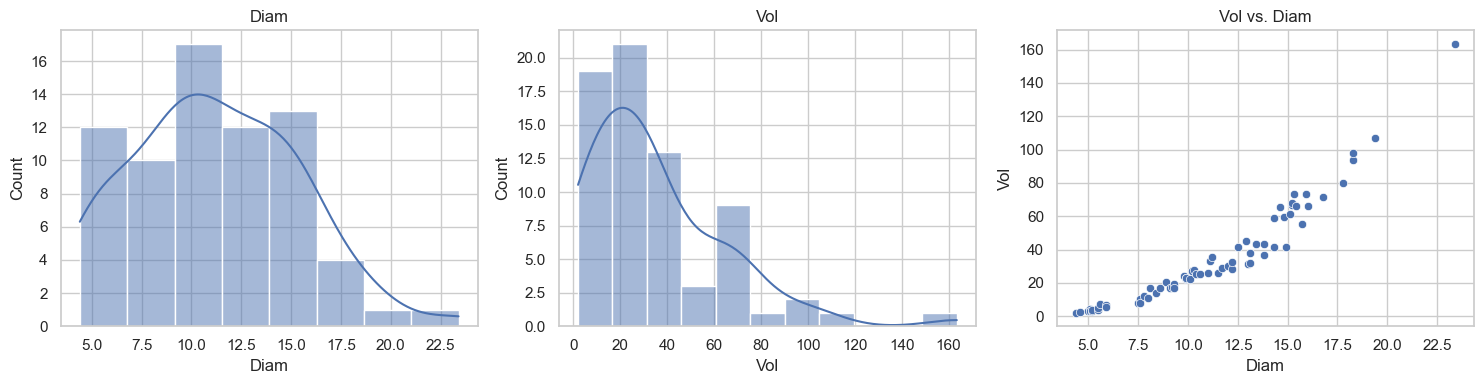

In [67]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(pines['Diam'], kde=True, ax=axes[0])
axes[0].set_title('Diam')

sns.histplot(pines['Vol'], kde=True, ax=axes[1])
axes[1].set_title('Vol')

sns.scatterplot(x='Diam', y='Vol', data=pines, ax=axes[2])
axes[2].set_title('Vol vs. Diam')

plt.tight_layout()
plt.show()

In [68]:
#Vol / Diam^2: volume ~ Diam^2 * height, so a plausible tree should have a ratio similar to trees of similar size
ratio = pines['Vol'] / (pines['Diam']**2)
thickest = pines['Diam'].idxmax()

print(f"Vol / Diam^2: median = {ratio.median():.3f}, max = {ratio.max():.3f}")
pd.DataFrame({'Diam': pines['Diam'], 'Vol': pines['Vol'], 'Vol/Diam^2': ratio}).tail(15)

Vol / Diam^2: median = 0.224, max = 0.313


,Diam,Vol,Vol/Diam^2
55,14.9,41.4,0.186478
56,15.1,61.5,0.269725
57,15.2,66.7,0.288695
58,15.2,68.2,0.295187
59,15.3,73.2,0.312700
60,15.4,65.9,0.277871
61,15.7,55.5,0.225161
62,15.9,73.6,0.291128
63,16.0,65.9,0.257422
64,16.8,71.4,0.252976


Pouze kontrola, zda vyhodit outlier, či ne. **Rozhodnutí:** nevyhodit - z tabulky poměrů nevyčnívá

In [69]:
model1 = smf.ols('Vol ~ Diam', data=pines).fit()
print(model1.summary())

                            OLS Regression Results                            
Dep. Variable:                    Vol   R-squared:                       0.893
Model:                            OLS   Adj. R-squared:                  0.891
Method:                 Least Squares   F-statistic:                     564.9
Date:                Sat, 17 Oct 2026   Prob (F-statistic):           1.17e-34
Time:                        16:15:31   Log-Likelihood:                -258.61
No. Observations:                  70   AIC:                             521.2
Df Residuals:                      68   BIC:                             525.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -41.5681      3.427    -12.130      0.0

In [70]:
x = pines['Diam'].to_numpy()
y = pines['Vol'].to_numpy()
n = len(x)

x_mean, y_mean = x.mean(), y.mean()
S_xx = np.sum((x - x_mean) ** 2)
S_xy = np.sum((x - x_mean) * (y - y_mean))
beta1_hat = S_xy / S_xx
beta0_hat = y_mean - beta1_hat * x_mean
y_hat = beta0_hat + beta1_hat * x

SST = np.sum((y - y_mean) ** 2)
SSR = np.sum((y_hat - y_mean) ** 2)
SSE = np.sum((y - y_hat) ** 2)

df_R = 1
df_E = n - 2
MSR = SSR / df_R
MSE = SSE / df_E
F = MSR / MSE
p_F = stats.f.sf(F, df_R, df_E)

print(f"SST = {SST:.4f}, SSR + SSE = {SSR + SSE:.4f}")

anova_hand = pd.DataFrame({'df': [df_R, df_E],
                           'sum_sq': [SSR, SSE],
                           'mean_sq': [MSR, MSE],
                           'F': [F, np.nan],
                           'PR(>F)': [p_F, np.nan]},
                          index=['Diam', 'Residual'])
display(anova_hand)

SST = 61713.5087, SSR + SSE = 61713.5087


,df,sum_sq,mean_sq,F,PR(>F)
Diam,1,55082.650383,55082.650383,564.87713,1.170769e-34
Residual,68,6630.858331,97.512623,NaN,NaN


In [71]:
sm.stats.anova_lm(model1)

,df,sum_sq,mean_sq,F,PR(>F)
Diam,1.0,55082.650383,55082.650383,564.87713,1.170769e-34
Residual,68.0,6630.858331,97.512623,NaN,NaN


In [72]:
R2_table = pd.DataFrame({'R2': [SSR / SST,
                                1 - SSE / SST,
                                np.corrcoef(x, y)[0, 1] ** 2,
                                model1.rsquared]},
                        index=['SSR/SST', '1 - SSE/SST', 'rho^2(x, y)', 'statsmodels'])
R2_table

,R2
SSR/SST,0.892554
1 - SSE/SST,0.892554
"rho^2(x, y)",0.892554
statsmodels,0.892554


In [73]:
se_beta1_hat = np.sqrt(MSE / S_xx)
T1 = beta1_hat / se_beta1_hat

print(f"T1 = {T1:.4f}, T1^2 = {T1 ** 2:.4f}")
print(f"F (by hand) = {F:.4f}, F (statsmodels) = {model1.fvalue:.4f}")

T1 = 23.7671, T1^2 = 564.8771
F (by hand) = 564.8771, F (statsmodels) = 564.8771


## Task 02 - Is a large $R^2$ a good model?
$R^2$ of Task 01 is close to 0.9. Plot the data with the fitted line and draw the studentized residuals against `Diam` and against the fitted values, and a Q-Q plot. What do the plots show about linearity and about constant variance? What does the fitted line predict for the thinnest trees in the data, and does that make physical sense? Relate your answer to the part of Lecture 4 on checking model adequacy.

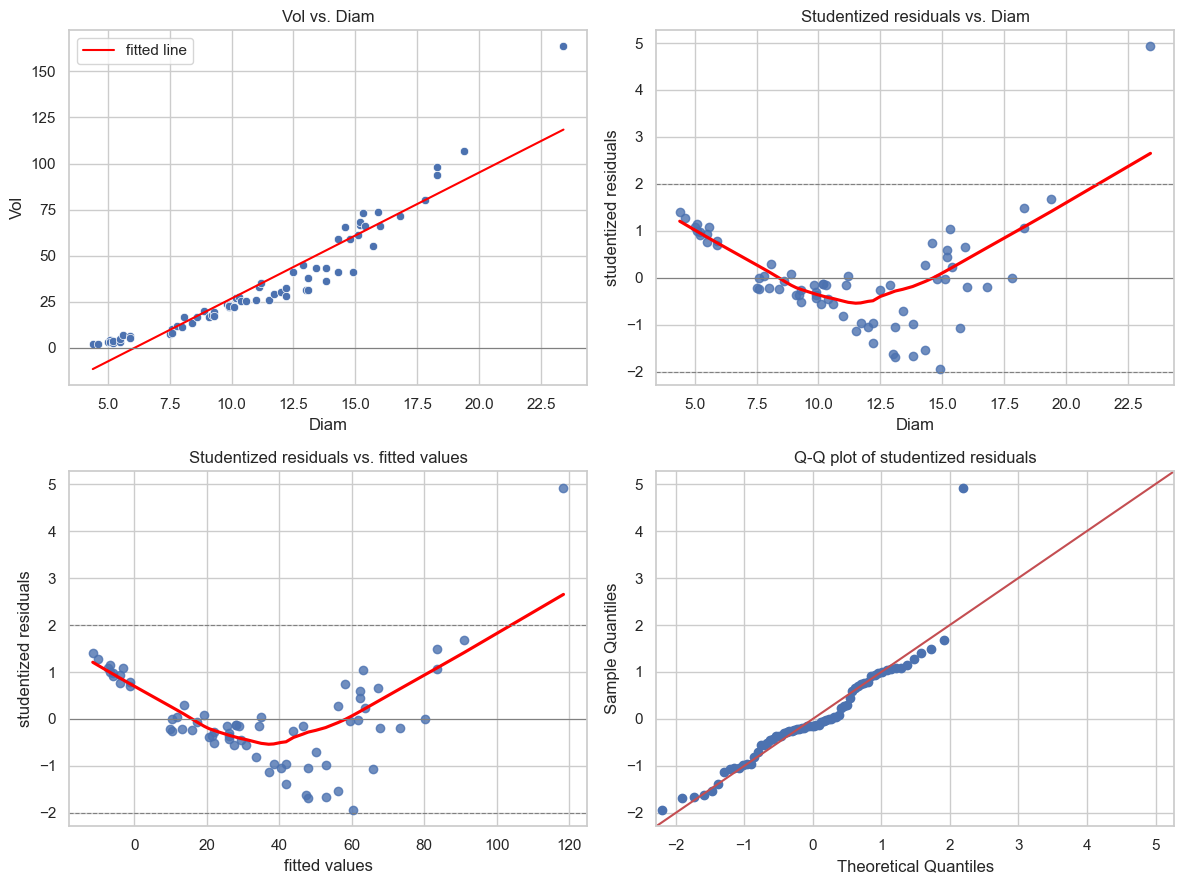

In [74]:
r1 = model1.get_influence().resid_studentized_internal
fitted1 = model1.fittedvalues
x_line = np.linspace(x.min(), x.max(), 100)

fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sns.scatterplot(x='Diam', y='Vol', data=pines, ax=axes[0, 0])
axes[0, 0].plot(x_line, model1.params['Intercept'] + model1.params['Diam'] * x_line, color='red', label='fitted line')
axes[0, 0].axhline(0, color='grey', lw=0.8)
axes[0, 0].set_title('Vol vs. Diam')
axes[0, 0].legend()

# red curve = lowess smoother, should be flat around 0 if the line is adequate
sns.regplot(x=x, y=r1, lowess=True, ax=axes[0, 1], line_kws={'color': 'red'})
axes[0, 1].set(xlabel='Diam', ylabel='studentized residuals', title='Studentized residuals vs. Diam')

sns.regplot(x=fitted1, y=r1, lowess=True, ax=axes[1, 0], line_kws={'color': 'red'})
axes[1, 0].set(xlabel='fitted values', ylabel='studentized residuals', title='Studentized residuals vs. fitted values')

for ax in [axes[0, 1], axes[1, 0]]:
    ax.axhline(0, color='grey', lw=0.8)
    ax.axhline(2, color='grey', ls='--', lw=0.8)
    ax.axhline(-2, color='grey', ls='--', lw=0.8)

sm.qqplot(r1, line='45', ax=axes[1, 1])
axes[1, 1].set_title('Q-Q plot of studentized residuals')

plt.tight_layout()
plt.show()

In [75]:
# thinnest trees
diam_zero = -model1.params['Intercept'] / model1.params['Diam']  # where the line crosses Vol = 0
print(f"Fitted line crosses Vol = 0 at Diam = {diam_zero:.2f} in")
print(f"Trees with negative fitted volume: {(fitted1 < 0).sum()} of {n}")

thin = pines.nsmallest(8, 'Diam').copy()
thin['Vol_fitted'] = model1.predict(thin)
thin

Fitted line crosses Vol = 0 at Diam = 6.08 in
Trees with negative fitted volume: 12 of 70


,Diam,Vol,Vol_fitted
0,4.4,2.0,-11.486532
1,4.6,2.2,-10.119189
2,5.0,3.0,-7.384501
3,5.1,4.3,-6.700830
4,5.1,3.0,-6.700830
5,5.2,2.9,-6.017158
6,5.2,3.5,-6.017158
7,5.5,3.4,-3.966143


Rezidua proti Diam i proti vyrovnaným hodnotám tvoří tvar U. Na okrajích jsou kladná, uprostřed (asi 10–14 palců) záporná. Vztah je zakřivený a přímka ho nevystihuje.

Rozptyl reziduí roste s průměrem stromu (tvar trychtýře). Předpoklad konstantního $\sigma^2$ splněn není. Q-Q plot je kromě nejtlustšího stromu ($r \approx 4.9$) v pohodě -> normalita problém nejspíše nebude.

Přímka protíná nulu u Diam ≈ 6.08 palce, takže 12 ze 70 stromů má záporný predikovaný objem. Například pro 4.4 palce vychází −11.5 ft³, skutečnost je 2.0 ft³. Fyzikálně to nedává smysl.

Vysoké $R^2 \approx 0.89$ neznamená, že je model vhodný. Adekvátnost se posuzuje z grafů reziduí, které by měly tvořit náhodný pás konstantní šířky kolem nuly. Tady mají rezidua jasnou strukturu (tvar U i rostoucí rozptyl), takže přímka vhodný model není.

## Task 03 - A model from geometry
The volume of a cylinder or a cone is proportional to the square of the diameter (times the height, which we do not have). Fit `Vol ~ I(Diam**2)`; this is still a simple linear regression, with the regressor $x_i = \mathrm{Diam}_i^2$. Compare it with Task 01: $R^2$, $s_n$, the residual plots. Is it legitimate to compare the two $R^2$ values here, and why (think of what $\mathrm{SST}$ is in both models)?

In [76]:
model2 = smf.ols('Vol ~ I(Diam**2)', data=pines).fit()

pd.DataFrame({'Vol ~ Diam': [model1.rsquared, np.sqrt(model1.scale), model1.centered_tss],
              'Vol ~ Diam^2': [model2.rsquared, np.sqrt(model2.scale), model2.centered_tss]},
             index=['R2', 's_n', 'SST'])

,Vol ~ Diam,Vol ~ Diam^2
R2,0.892554,0.966457
s_n,9.874848,5.517432
SST,61713.508714,61713.508714


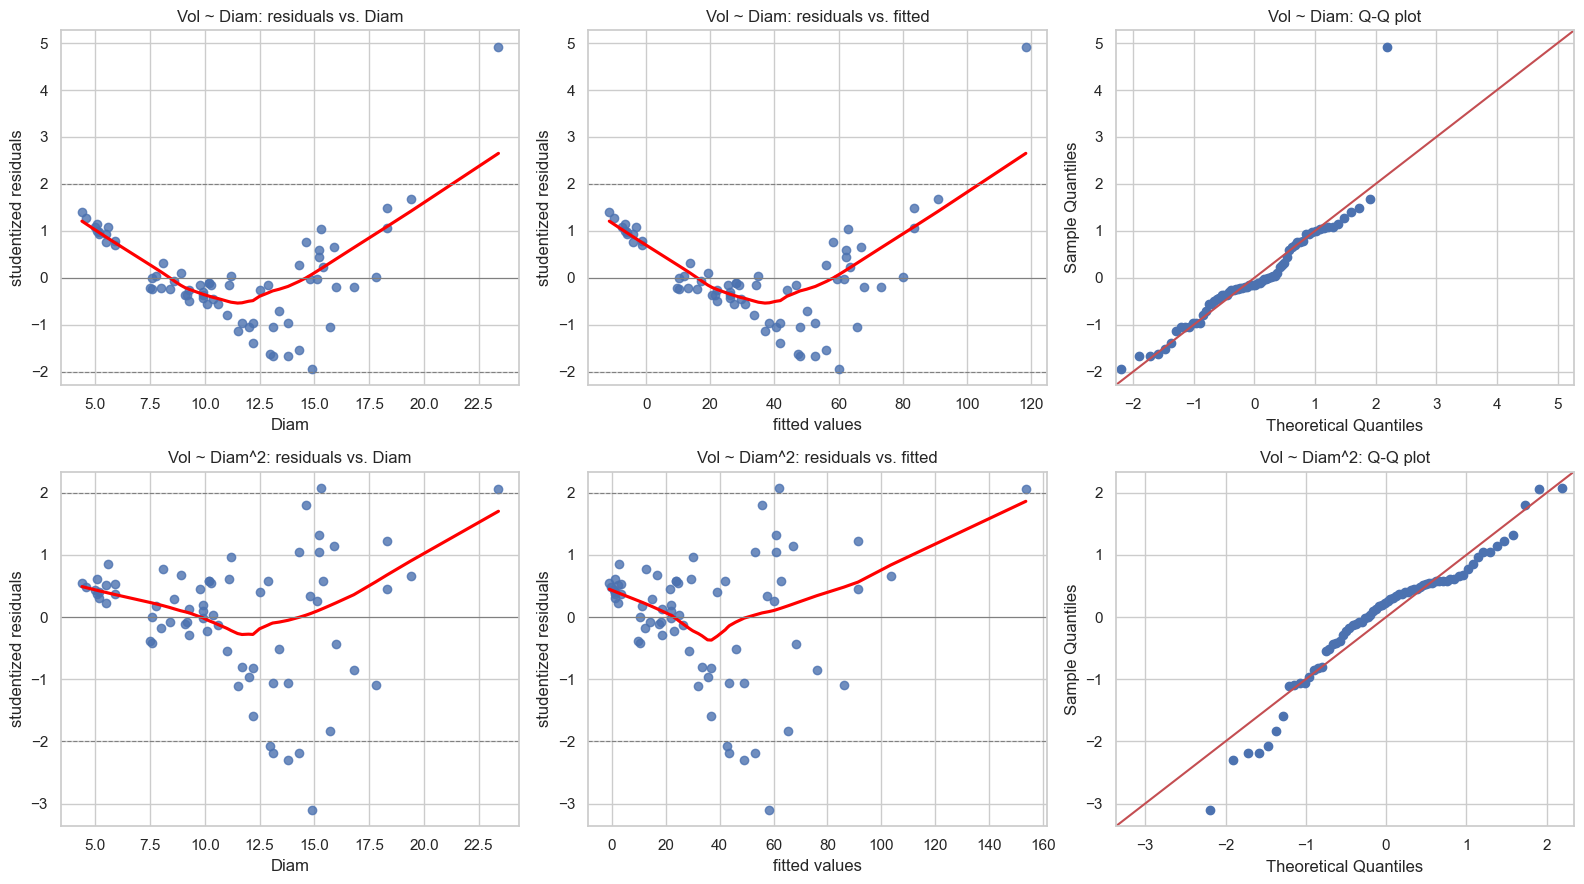

In [77]:
r2 = model2.get_influence().resid_studentized_internal
fitted2 = model2.fittedvalues

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for row, (name, r, fitted) in enumerate([('Vol ~ Diam', r1, fitted1), ('Vol ~ Diam^2', r2, fitted2)]):
    sns.regplot(x=x, y=r, lowess=True, ax=axes[row, 0], line_kws={'color': 'red'})
    axes[row, 0].set(xlabel='Diam', ylabel='studentized residuals', title=f'{name}: residuals vs. Diam')
    sns.regplot(x=fitted, y=r, lowess=True, ax=axes[row, 1], line_kws={'color': 'red'})
    axes[row, 1].set(xlabel='fitted values', ylabel='studentized residuals', title=f'{name}: residuals vs. fitted')
    for ax in axes[row, :2]:
        ax.axhline(0, color='grey', lw=0.8)
        ax.axhline(2, color='grey', ls='--', lw=0.8)
        ax.axhline(-2, color='grey', ls='--', lw=0.8)
    sm.qqplot(r, line='45', ax=axes[row, 2])
    axes[row, 2].set_title(f'{name}: Q-Q plot')

plt.tight_layout()
plt.show()

Podle $R^2$ a $s_n$ je lepší model $Diam^2$ - z definice $R^2$ modely mohu porovnat, jelikož mají stejné SST - dělím stejnou hodnotou, porovnávám jen rozdíl v SSE.

Tvar studentizovaných reziduí je znovu do U, nicméně méně. Pořád lze pozorovat rostoucí rozptyl.

## Task 04 - Through the origin
A tree with zero diameter has zero volume, so the model $\mathrm{Vol}_i = \beta_1 \mathrm{Diam}_i^2 + e_i$ without intercept is natural. Fit it and compute by hand $\widehat{\beta}_1 = \sum x_i y_i / \sum x_i^2$, $s_n^2 = \mathrm{SSE}/(n-1)$, the standard error of $\widehat{\beta}_1$, the decomposition $\sum y_i^2 = \sum \widehat{y}_i^2 + \sum \widehat{e}_i^2$ and the uncentred $R^2$; compare with `statsmodels`. Then compare the model with the model of Task 03: which has the larger `R-squared`, which has the smaller $s_n$, and which comparison is the fair one (Lecture 4, Remark 2.17)? Finally, test $H_0: \beta_0 = 0$ in the model of Task 03. Do the test and the geometric argument point the same way?

In [78]:
model3 = smf.ols('Vol ~ I(Diam**2) - 1', data=pines).fit()

x_sq = x ** 2
beta1_0 = np.sum(x_sq * y) / np.sum(x_sq ** 2)
y_hat_0 = beta1_0 * x_sq
SSE_0 = np.sum((y - y_hat_0) ** 2)
s_n2_0 = SSE_0 / (n - 1)
se_beta1_0 = np.sqrt(s_n2_0 / np.sum(x_sq ** 2))
R2_0 = np.sum(y_hat_0 ** 2) / np.sum(y ** 2)

print(f"sum y^2 = {np.sum(y ** 2):.2f}")
print(f"sum y_hat^2 + sum e^2 = {np.sum(y_hat_0 ** 2):.2f} + {SSE_0:.2f} = {np.sum(y_hat_0 ** 2) + SSE_0:.2f}")

pd.DataFrame({'by hand': [beta1_0, s_n2_0, se_beta1_0, R2_0],
              'statsmodels': [model3.params.iloc[0], model3.scale, model3.bse.iloc[0], model3.rsquared]},
             index=['beta1', 's_n2', 'SE(beta1)', 'R2 (uncentred)'])

sum y^2 = 146953.27
sum y_hat^2 + sum e^2 = 143861.49 + 3091.78 = 146953.27


,by hand,statsmodels
beta1,0.261354,0.261354
s_n2,44.808348,44.808348
SE(beta1),0.004612,0.004612
R2 (uncentred),0.978961,0.978961


In [79]:
pd.DataFrame({'Vol ~ Diam^2': [model2.rsquared, np.sqrt(model2.scale), np.corrcoef(y, model2.fittedvalues)[0, 1] ** 2],
              'Vol ~ Diam^2 - 1': [model3.rsquared, np.sqrt(model3.scale), np.corrcoef(y, model3.fittedvalues)[0, 1] ** 2]},
             index=['R-squared', 's_n', 'rho^2(y, y_hat)'])

,Vol ~ Diam^2,Vol ~ Diam^2 - 1
R-squared,0.966457,0.978961
s_n,5.517432,6.693904
"rho^2(y, y_hat)",0.966457,0.966457


R^2 podle očekávání (a znalosti z přednášky) vychází vyšší u modelu bez interceptu (ten počítá necentrované R^2 - dělí sumou y^2 místo SST). Je to ale zavádějící a s_n, správné kritérium, vychází lepší u modelu s interceptem.

$\rho^2(y, \hat{y})$ vychází stejně u obou modelů. Jsou to lineární funkce Diam^2, takže Pearsonův korelační koeficient vychází stejně.

In [80]:
T0 = model2.params['Intercept'] / model2.bse['Intercept']
t_crit = stats.t.ppf(0.975, df=n - 2)
p0 = 2 * stats.t.sf(abs(T0), df=n - 2)

print(f"beta0_hat = {model2.params['Intercept']:.4f}, SE = {model2.bse['Intercept']:.4f}")
print(f"T0 = {T0:.4f}, t_crit = {t_crit:.4f}, p = {p0:.4g}")

beta0_hat = -6.6451, SE = 1.1470
T0 = -5.7933, t_crit = 1.9955, p = 1.946e-07


Podle testu zamítáme H0 (p < 1e-06) a tudíž bychom správně měli zahrnout intercept.

Test a geometrie si odporují - intercept nemá žádný fyzikální význam. Tím, že objem roste rychleji než Diam^2, tak záporný intercept kompenzuje chybějící zakřivení. 

## Task 05 - Predictions
Choose one of the models of Tasks 03 and 04 and justify the choice in two sentences. For trees with diameters 8, 15 and 30 inches compute by hand the 95 % confidence interval for the mean volume and the 95 % prediction interval for the volume of one tree (with $n-2$ or $n-1$ degrees of freedom, according to your model), and check the numbers with `get_prediction`. Which of the three diameters is an extrapolation? Add the prediction of the straight line of Task 01 at 30 inches and comment on the difference.

Zvolen byl model 2 s interceptem - má menší s_n a test zamítá beta0=0. 30 palců je extrapolace (max diam = 23.4).

In [81]:
diam_new = np.array([8, 15, 30])
x0 = diam_new ** 2
x_sq_mean = x_sq.mean()
S_xx_sq = np.sum((x_sq - x_sq_mean) ** 2)
s_n = np.sqrt(model2.scale)
t_q = stats.t.ppf(0.975, df=n - 2)

y0_hat = model2.params['Intercept'] + model2.params['I(Diam ** 2)'] * x0
se_mean = s_n * np.sqrt(1 / n + (x0 - x_sq_mean) ** 2 / S_xx_sq)
se_pred = s_n * np.sqrt(1 + 1 / n + (x0 - x_sq_mean) ** 2 / S_xx_sq)

pd.DataFrame({'Diam': diam_new, 'mean': y0_hat,
              'ci_lower': y0_hat - t_q * se_mean, 'ci_upper': y0_hat + t_q * se_mean,
              'pi_lower': y0_hat - t_q * se_pred, 'pi_upper': y0_hat + t_q * se_pred})

,Diam,mean,ci_lower,ci_upper,pi_lower,pi_upper
0,8,12.087627,10.417619,13.757635,0.951827,23.223427
1,15,59.212033,57.499324,60.924743,48.069750,70.354317
2,30,256.783303,246.694041,266.872566,241.849773,271.716833


In [82]:
model2.get_prediction(pd.DataFrame({'Diam': diam_new})).summary_frame(alpha=0.05)

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,12.087627,0.836900,10.417619,13.757635,0.951827,23.223427
1,59.212033,0.858299,57.499324,60.924743,48.069750,70.354317
2,256.783303,5.056086,246.694041,266.872566,241.849773,271.716833


In [83]:
print(f"Diam in data: {x.min()} - {x.max()}")

new_30 = pd.DataFrame({'Diam': [30]})
pd.concat([model2.get_prediction(new_30).summary_frame(alpha=0.05),
           model1.get_prediction(new_30).summary_frame(alpha=0.05)],
          keys=['Vol ~ Diam^2', 'Vol ~ Diam']).droplevel(1)

Diam in data: 4.4 - 23.4


,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
Vol ~ Diam^2,256.783303,5.056086,246.694041,266.872566,241.849773,271.716833
Vol ~ Diam,163.533442,5.539613,152.479316,174.587567,140.939663,186.127220


Oba modely dávají různé výsledky a ani CI se nepřekrývají. 

Přímka předpovídá 163.5 pro strom s průměrem 30. To je ale objem nejtlustšího stromu v datech (ten "outlier"), který má průměr 23.4. To souvisí s tvarem reziduí - model podhodnocuje v pravém okraji.

## Task 06 - Bands
Plot the data with the fitted curve of your model on the original scale (`Diam` on the horizontal axis) together with the 95 % confidence band for the mean and the 95 % prediction band. Where are the bands narrowest and why? Why does the prediction band not shrink towards the curve if we measured many more trees?

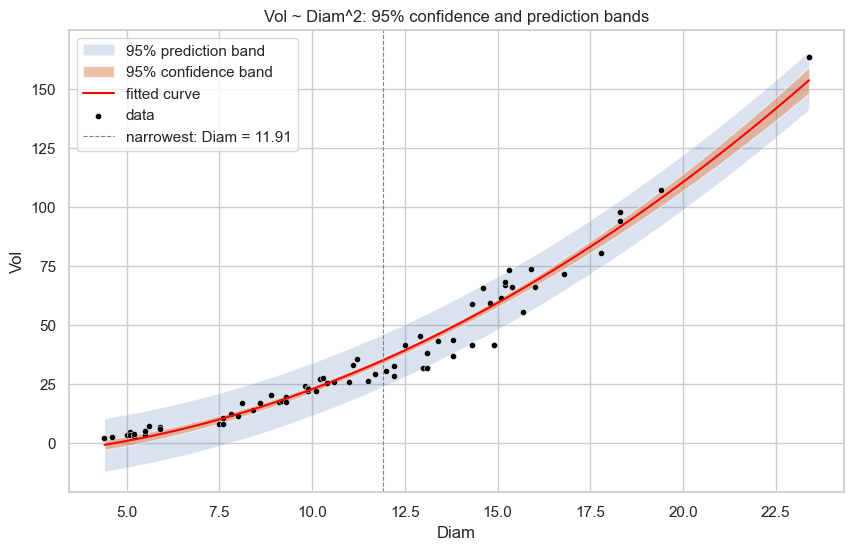

CI half-width: min = 1.32, max = 5.51
PI half-width: min = 11.09, max = 12.31, t * s_n = 11.01


In [84]:
diam_grid = np.linspace(x.min(), x.max(), 200)
bands = model2.get_prediction(pd.DataFrame({'Diam': diam_grid})).summary_frame(alpha=0.05)
diam_narrow = np.sqrt(x_sq_mean)

plt.figure(figsize=(10, 6))
plt.fill_between(diam_grid, bands['obs_ci_lower'], bands['obs_ci_upper'], alpha=0.2, label='95% prediction band')
plt.fill_between(diam_grid, bands['mean_ci_lower'], bands['mean_ci_upper'], alpha=0.5, label='95% confidence band')
plt.plot(diam_grid, bands['mean'], color='red', label='fitted curve')
sns.scatterplot(x='Diam', y='Vol', data=pines, color='black', s=20, label='data')
plt.axvline(diam_narrow, color='grey', ls='--', lw=0.8, label=f'narrowest: Diam = {diam_narrow:.2f}')
plt.xlabel('Diam')
plt.ylabel('Vol')
plt.title('Vol ~ Diam^2: 95% confidence and prediction bands')
plt.legend()
plt.show()

ci_half = (bands['mean_ci_upper'] - bands['mean_ci_lower']) / 2
pi_half = (bands['obs_ci_upper'] - bands['obs_ci_lower']) / 2
print(f"CI half-width: min = {ci_half.min():.2f}, max = {ci_half.max():.2f}")
print(f"PI half-width: min = {pi_half.min():.2f}, max = {pi_half.max():.2f}, t * s_n = {t_q * s_n:.2f}")

Pásy jsou nejužší v bodě, kde regresor Diam² je roven svému průměru, tj. pro Diam = √(průměr Diam²) ≈ 11.91 palce (ne v průměru Diam = 11.18), protože tam je člen (x₀ − x̄)²/Sₓₓ nulový. 

Šířka konfidenčního pásu závisí jen na 1/n + (x₀ − x̄)²/Sₓₓ, takže s rostoucím počtem stromů jde k nule. Predikční pás obsahuje navíc člen 1, tedy rozptyl σ² jednotlivého stromu kolem střední hodnoty (jiná výška, tvar kmene), který další měření neodstraní. Predikční pás se proto blíží ±1.96·σ ≈ ±10.8 ft³; už teď je jeho minimální poloviční šířka 11.09 ft³.

Graf zároveň ukazuje slabiny modelu: predikční pás jde u nejtenčích stromů pod nulu a má téměř konstantní šířku, přestože rozptyl dat s průměrem zjevně roste. U tenkých stromů je tedy zbytečně široký, u tlustých příliš úzký (viz Task 07).


## Task 07 - Does the prediction interval keep its promise?
The residual plots of Tasks 02 and 03 suggest that the spread of the volume grows with the diameter. Compute, for the model of Task 05, the share of the 70 trees that lie inside their own 95 % prediction interval, separately for trees with `Diam` below 10 inches and above 14 inches. What does the result say about prediction intervals for thin and for thick trees under non-constant variance? (Remedies such as transformations and weighted least squares come later in the course; a short reflection is enough.)

In [85]:
pi_own = model2.get_prediction(pines).summary_frame(alpha=0.05)
inside = ((y >= pi_own['obs_ci_lower']) & (y <= pi_own['obs_ci_upper'])).to_numpy()

groups = {'all': x > 0, 'Diam < 10': x < 10, '10 <= Diam <= 14': (x >= 10) & (x <= 14), 'Diam > 14': x > 14}
pd.DataFrame({'n': [m.sum() for m in groups.values()],
              'inside PI': [inside[m].sum() for m in groups.values()],
              'share': [inside[m].mean() for m in groups.values()]},
             index=groups.keys())

,n,inside PI,share
all,70,64,0.914286
Diam < 10,29,29,1.000000
10 <= Diam <= 14,22,19,0.863636
Diam > 14,19,16,0.842105


PI má skoro konstantní šířku, protože používá jedno s_n pro všechny stromy. Rozptyl objemu ale s průměrem roste. U tenkých stromů je tak PI zbytečně široký (a k ničemu - strom s objemem 3 dostane interval cca od -10 do 12), u tlustých příliš úzký -> 95 % pro ně neplatí. Celkových 91 % jen zprůměruje dvě chyby opačným směrem.

Řešení: transformace (např. log Vol ~ log Diam)

## Task 08 - Normality matters for prediction intervals
Lecture 4 (Remark 2.20) states that the confidence interval for $\mathrm{E}\,Y_0$ is approximately valid for large $n$ even with non-normal errors, whereas the prediction interval for $Y_0$ relies on normality for any $n$. Check this by simulation. Take the fitted parameters of the model of Task 03 as the true ones and the 70 diameters as a fixed design. Generate 5000 samples with errors (a) normal with standard deviation $s_n$, (b) $s_n(\varepsilon - 1)$ with $\varepsilon$ exponential with mean 1 (same variance, skewed). In each sample fit the model, compute both 95 % intervals at `Diam` = 15, generate one new observation $Y_0$ there, and record whether the confidence interval covers $\mathrm{E}\,Y_0$ and whether the prediction interval covers $Y_0$. Report the four coverage rates. Also look at how often the new observation falls *below* and *above* the prediction interval in case (b), and explain the asymmetry.

In [86]:
rng = np.random.default_rng(42)
n_sim = 5000
b0_true, b1_true = model2.params
x0_15 = 15 ** 2
EY0 = b0_true + b1_true * x0_15
h0 = 1 / n + (x0_15 - x_sq_mean) ** 2 / S_xx_sq


def draw_errors(kind, size):
    if kind == 'normal':
        return rng.normal(0, s_n, size)
    return s_n * (rng.exponential(1, size) - 1)


rows = []
for kind in ['normal', 'exponential']:
    ci_cover, below, above = np.zeros(n_sim, bool), np.zeros(n_sim, bool), np.zeros(n_sim, bool)
    for i in range(n_sim):
        y_sim = b0_true + b1_true * x_sq + draw_errors(kind, n)
        b1 = np.sum((x_sq - x_sq_mean) * (y_sim - y_sim.mean())) / S_xx_sq
        b0 = y_sim.mean() - b1 * x_sq_mean
        s = np.sqrt(np.sum((y_sim - b0 - b1 * x_sq) ** 2) / (n - 2))
        y0_hat = b0 + b1 * x0_15
        y0_new = EY0 + draw_errors(kind, 1)[0]
        ci_cover[i] = abs(y0_hat - EY0) <= t_q * s * np.sqrt(h0)
        below[i] = y0_new < y0_hat - t_q * s * np.sqrt(1 + h0)
        above[i] = y0_new > y0_hat + t_q * s * np.sqrt(1 + h0)
    rows.append({'errors': kind, 'CI covers E Y0': ci_cover.mean(), 'PI covers Y0': 1 - below.mean() - above.mean(),
                 'Y0 below PI': below.mean(), 'Y0 above PI': above.mean()})

pd.DataFrame(rows).set_index('errors')

,CI covers E Y0,PI covers Y0,Y0 below PI,Y0 above PI
errors,,,,
normal,0.9480,0.9470,0.0284,0.0246
exponential,0.9452,0.9386,0.0000,0.0614


CI: V obou případech pokrývá E Y0 cca z 95 % (94.8 % normální, 94.5 % exponenciální), takže díky CLT jsou pro n = 70 "normální" i při šikmých chybách.

PI: U normálních chyb 94.7 % a nepokrytí je symetrické (2.8 % pod, 2.5 % nad). U exponenciálních 93.9 %. Monte Carlo chyba je cca 0.3 p.b. -> odchylka od 95 % je skutečná, u CI ne.

Asymetrie: V případě (b) nespadne Y0 pod PI ani jednou, nad něj v 6.1 %. Chyba s_n(eps - 1) je zdola omezená -s_n, nemůže tedy být víc než cca 5.5 pod E Y0. Dolní mez PI je ale cca 11 pod predikcí -> nedosažitelná. Exponenciála má naopak dlouhý pravý chvost, takže všechno nepokrytí jde nahoru. Teoreticky by to bylo cca e^(-3) ≈ 5 %, v simulaci 6.1 %, protože při šikmých chybách s víc kolísá a občas PI podhodnotí.

Proč CLT nepomůže: Y0 je jedno nové pozorování, jeho chyba se s ničím neprůměruje. S rostoucím n se jen zpřesní beta_hat a s, takže PI jde k symetrickému ±1.96 sigma. Skutečné rozdělení Y0 ale zůstává šikmé. PI je tedy špatně tvarem, ne jen šířkou - a to platí pro jakékoli n.
